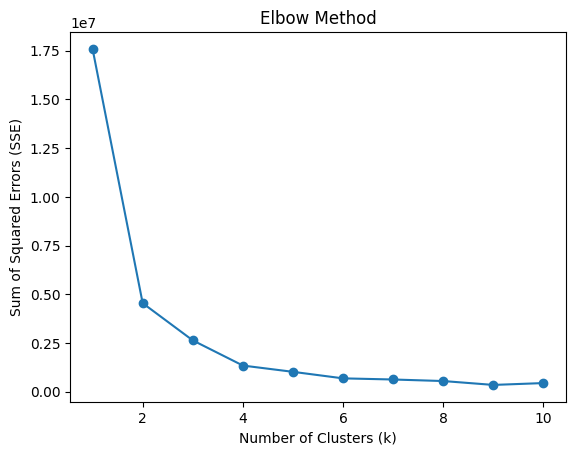

Optimal number of clusters (Elbow Method): 3


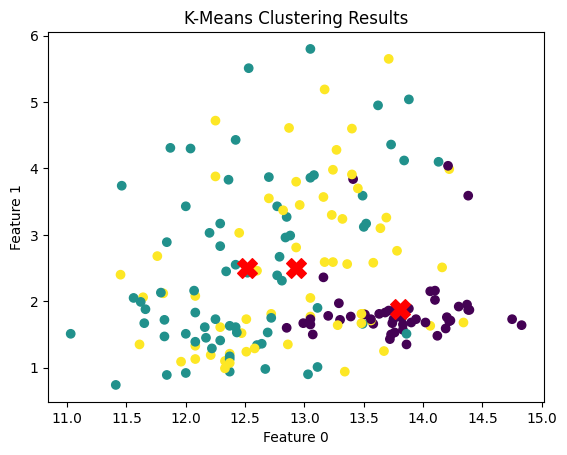

In [4]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

def euclidean_distance(x1, x2):
    return np.sqrt(np.sum((x1 - x2)**2))

def initialize_centroids(X, k):
    indices = np.random.choice(len(X), k, replace=False) #This function randomly selects k data points from the dataset X as initial centroids.
    return X[indices]# generates an array of k unique indices chosen randomly from the range [0, len(X))
# replace=False argument ensures that each index is selected only once
def k_means(X, k, max_iters=100):
    centroids = initialize_centroids(X, k)
    for _ in range(max_iters):
        # Calculate distances from each data point to all centroids
        distances = np.array([np.sum((X - c)**2, axis=1) for c in centroids]).T

        # Assign each data point to the nearest centroid
        labels = np.argmin(distances, axis=1)

        # Update centroids based on the mean of data points assigned to each centroid
        new_centroids = np.array([np.mean(X[labels == i], axis=0) for i in range(k)])

        # Check for convergence
        if np.all(centroids == new_centroids):
            break

        centroids = new_centroids

    return centroids, labels

def calculate_sse(X, centroids, labels):
    sse = 0 #measure of how far each data point is from its assigned centroid.
    for i in range(len(centroids)):
        sse += np.sum((X[labels == i] - centroids[i])**2)
    return sse

# Load dataset
file_path = "/content/drive/MyDrive/Kmean_dataset.csv"
df = pd.read_csv(file_path)

# Extract features
X = df.values

# Choose the optimal number of clusters using the elbow method
sse_values = []
max_clusters = 10

for k in range(1, max_clusters + 1):
    centroids, labels = k_means(X, k)
    sse = calculate_sse(X, centroids, labels)
    sse_values.append(sse)

# Plot elbow method
plt.plot(range(1, max_clusters + 1), sse_values, marker='o')
plt.xlabel('Number of Clusters (k)')
plt.ylabel('Sum of Squared Errors (SSE)')
plt.title('Elbow Method')
plt.show()

# Choose the optimal number of clusters based on the elbow method
optimal_k = 3  # You can change this based on the plot
print(f"Optimal number of clusters (Elbow Method): {optimal_k}")

# Run k-means with the optimal number of clusters
final_centroids, final_labels = k_means(X, optimal_k)

# Visualize the results (2D scatter plot for simplicity)
# Replace the indices (0 and 1) with the relevant feature indices for your dataset
plt.scatter(X[:, 0], X[:, 1], c=final_labels, cmap='viridis')
plt.scatter(final_centroids[:, 0], final_centroids[:, 1], marker='X', s=200, c='red')
plt.title('K-Means Clustering Results')
plt.xlabel('Feature 0')
plt.ylabel('Feature 1')
plt.show()


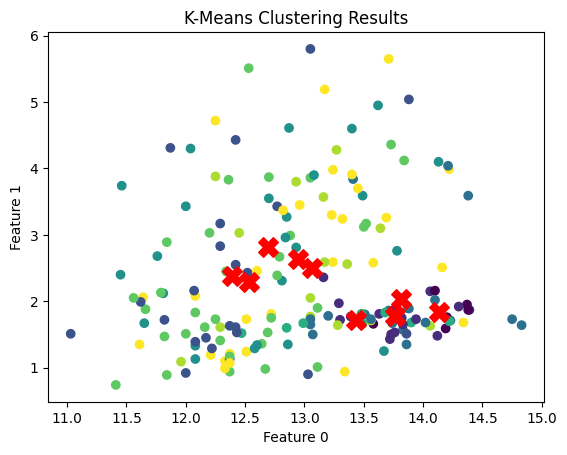

Silhouette Coefficient: 0.8378260229866437


In [3]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# The dataset is loaded
dataset_path = "/content/drive/MyDrive/Kmean_dataset.csv"
data = pd.read_csv(dataset_path)

# Extract features from the dataset
X = data.values

# Function to calculate Euclidean distance
def euclidean_distance(x1, x2):
    return np.sqrt(np.sum((x1 - x2)**2))

# Function to calculate the silhouette coefficient for each point
def silhouette_coefficient(data, labels, centroids):
    num_points = len(data)
    silhouette_vals = np.zeros(num_points)

    # Loop through each data point to calculate the silhouette coefficient
    for i in range(num_points):
        # Calculate the average distance to other points in the same cluster (a_i)
        a_i = np.mean([euclidean_distance(data[i], data[j]) for j in range(num_points) if labels[j] == labels[i]])

        # Calculate the average distance to points in the nearest different cluster (b_i)
        b_i = min([np.mean([euclidean_distance(data[i], data[k]) for k in range(num_points) if labels[k] != labels[i]]) for i in range(num_points)])

        # Calculate the silhouette coefficient for the current point
        silhouette_vals[i] = (b_i - a_i) / max(a_i, b_i)

    return silhouette_vals

# K-Means clustering function
def kmeans_clustering(data, k, max_iters=100):
    num_points, num_features = data.shape

    # Initialize centroids randomly
    centroids = data[np.random.choice(num_points, k, replace=False)]

    # Iterate to update centroids and assign points to clusters
    for _ in range(max_iters):
        # Assign each point to the nearest centroid
        labels = np.argmin(np.linalg.norm(data[:, np.newaxis] - centroids, axis=2), axis=1)

        # Update centroids based on the mean of assigned points
        new_centroids = np.array([np.mean(data[labels == j], axis=0) for j in range(k)])

        # Check for convergence; break if centroids do not change
        if np.all(centroids == new_centroids):
            break

        centroids = new_centroids

    return labels, centroids

# Set the number of clusters (you can change this)
k = 9

# Perform K-Means clustering
final_labels, final_centroids = kmeans_clustering(X, k)

# Visualize the results (2D scatter plot for simplicity)
feature_indices = [0, 1]  # Change these indices as needed
plt.scatter(X[:, feature_indices[0]], X[:, feature_indices[1]], c=final_labels, cmap='viridis')
plt.scatter(final_centroids[:, feature_indices[0]], final_centroids[:, feature_indices[1]], marker='X', s=200, c='red')
plt.title('K-Means Clustering Results')
plt.xlabel(f'Feature {feature_indices[0]}')
plt.ylabel(f'Feature {feature_indices[1]}')
plt.show()

# Calculate silhouette coefficient
silhouette_vals = silhouette_coefficient(X, final_labels, final_centroids)
average_silhouette = np.mean(silhouette_vals)

# Output the average silhouette coefficient
print(f"Silhouette Coefficient: {average_silhouette}")



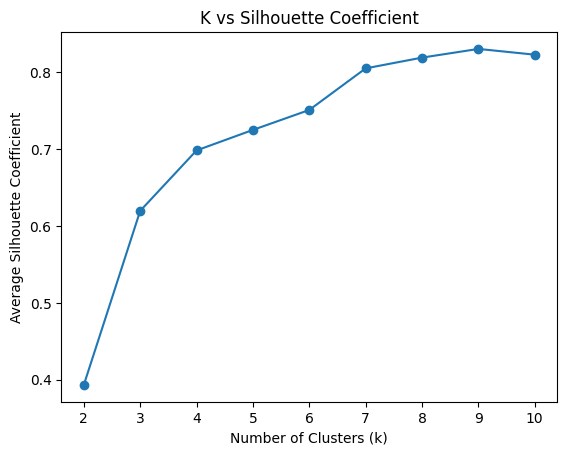

In [ ]:
def average_silhouette_for_k(data, k):
    labels, centroids = kmeans_clustering(data, k)
    silhouette_vals = silhouette_coefficient(data, labels, centroids)
    return np.mean(silhouette_vals)

# Range of clusters to try
k_values = range(2, 11)  # You can adjust this range as needed

# Calculate average silhouette coefficient for each k
silhouette_scores = [average_silhouette_for_k(X, k) for k in k_values]

# Plotting k vs silhouette coefficient
plt.plot(k_values, silhouette_scores, marker='o')
plt.title('K vs Silhouette Coefficient')
plt.xlabel('Number of Clusters (k)')
plt.ylabel('Average Silhouette Coefficient')
plt.show()